# Market analysis: imports Spain ← China

**Goal:** identify, with data, which product categories have the most potential
to import from China into Spain — instead of deciding by intuition.

This notebook walks through the analysis step by step:
1. Loading trade data
2. Feature engineering per sector
3. Market-attractiveness scoring
4. Visualisation and strategic interpretation

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from product_catalogue import get_valid_hs_codes, label_for, group_for
from market_scoring import build_features, score_markets, ScoringWeights
from synthetic_data import generate_trade_data

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. Loading data

For the demo we use synthetic data (reproducible, runs offline). On your own
machine, swap this cell for `EurostatClient` to work with real data:

```python
from eurostat_client import EurostatClient, INDICATOR_VALUE, INDICATOR_QTY
client = EurostatClient()
codes = get_valid_hs_codes()
years = ["2020","2021","2022","2023","2024"]
value_df = client.get_imports("ES", "CN", codes, years, INDICATOR_VALUE)
qty_df   = client.get_imports("ES", "CN", codes, years, INDICATOR_QTY)
```

In [2]:
value_df, qty_df = generate_trade_data(years=[2020, 2021, 2022, 2023, 2024])
print(f"Value: {len(value_df)} rows | Quantity: {len(qty_df)} rows")
value_df.head()

Value: 120 rows | Quantity: 120 rows


,reporter,partner,product,flow,year,indicator,value
0,ES,CN,9401,import,2020,VALUE_IN_EUROS,"203,771,831.00"
1,ES,CN,9401,import,2021,VALUE_IN_EUROS,"187,187,956.00"
2,ES,CN,9401,import,2022,VALUE_IN_EUROS,"202,733,761.00"
3,ES,CN,9401,import,2023,VALUE_IN_EUROS,"202,884,547.00"
4,ES,CN,9401,import,2024,VALUE_IN_EUROS,"226,506,036.00"


## 2. Feature engineering

For each category we compute: growth (CAGR), momentum (recent acceleration),
unit price and market size. These are the signals we'll later combine.

In [3]:
features = build_features(value_df, qty_df)
features["label"] = features["product"].map(label_for)
features["group"] = features["product"].map(group_for)
features[["label", "group", "cagr", "momentum", "unit_price", "value_latest"]].head(10)

,label,group,cagr,momentum,unit_price,value_latest
0,Plastic articles for home and kitchen,Home,0.10,0.27,8.91,"188,770,161.00"
1,"Bags, suitcases and leather goods",Accessories,0.03,0.02,15.32,"229,152,015.00"
2,Wood marquetry and decorative objects,Decoration,0.10,0.28,13.71,"252,197,329.00"
3,Knitted gloves,Textile,0.01,-0.01,7.44,"135,579,875.00"
4,"Bed, table and bath linen",Home textile,0.05,0.08,7.87,"235,442,783.00"
5,Footwear with textile uppers,Footwear,0.04,0.09,10.73,"264,707,379.00"
6,Umbrellas and parasols,Sport & leisure,0.10,0.18,25.12,"341,757,200.00"
7,Porcelain tableware,Home,0.07,0.19,8.02,"179,706,270.00"
8,Ceramic statuettes and decorative objects,Decoration,0.08,0.21,14.76,"267,996,838.00"
9,Glassware for table and kitchen,Home,0.05,0.13,10.02,"168,656,942.00"


## 3. Scoring

We combine the signals into a 0-100 score. Weights are configurable: here we
prioritise growth and momentum, but you can raise the price weight if you're
after high margin.

In [4]:
weights = ScoringWeights(growth=0.35, size=0.20, momentum=0.25, price=0.20)
scored = score_markets(features, weights)
scored["label"] = scored["product"].map(label_for)
scored["group"] = scored["product"].map(group_for)
scored[["label", "group", "score", "cagr", "value_latest"]].head(10)

,label,group,score,cagr,value_latest
0,Electrical cables and conductors,Electronics,95.51,0.16,"233,305,755.00"
1,Phones and communication equipment,Electronics,77.78,0.10,"353,908,563.00"
2,Computers and peripherals,Electronics,69.50,0.11,"112,090,482.00"
3,Sports and gym articles,Sport & leisure,63.82,0.14,"87,104,970.00"
4,Umbrellas and parasols,Sport & leisure,62.73,0.10,"341,757,200.00"
5,Bicycles (non-motorised),Sport & leisure,59.93,0.14,"55,263,608.00"
6,Wood marquetry and decorative objects,Decoration,59.66,0.10,"252,197,329.00"
7,Festive and seasonal decoration articles,Decoration,58.91,0.09,"271,565,996.00"
8,Toys and scale models,Sport & leisure,55.77,0.09,"179,670,207.00"
9,Ceramic statuettes and decorative objects,Decoration,54.43,0.08,"267,996,838.00"


## 4. Strategic visualisation

### Attractiveness ranking

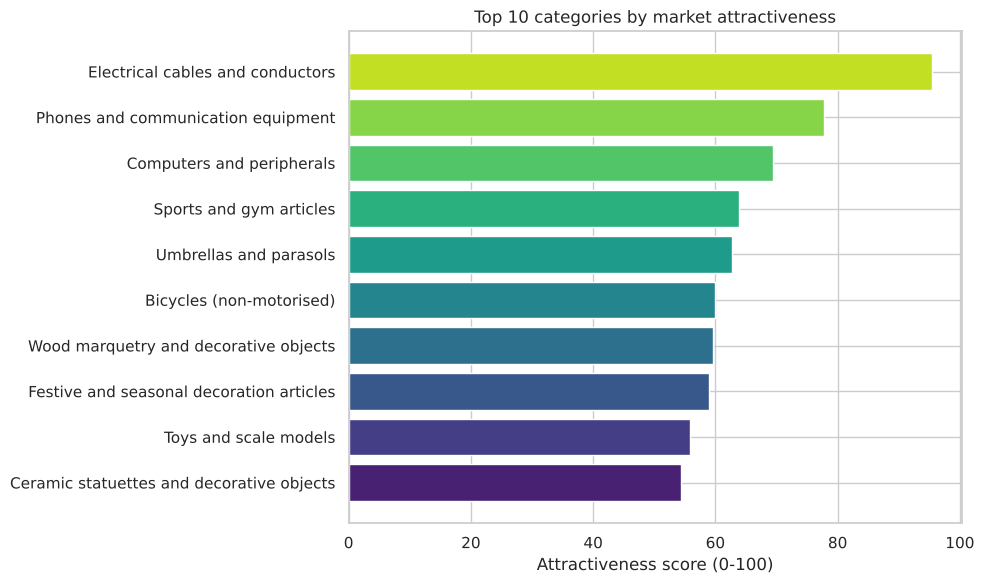

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
top = scored.head(10).iloc[::-1]
ax.barh(top["label"], top["score"], color=sns.color_palette("viridis", len(top)))
ax.set_xlabel("Attractiveness score (0-100)")
ax.set_title("Top 10 categories by market attractiveness")
plt.tight_layout()
plt.show()

### Opportunity map: growth vs size

The key chart. Categories in the top-right quadrant (high growth + large market)
are the strongest opportunities. Point size is unit price (value-added proxy).

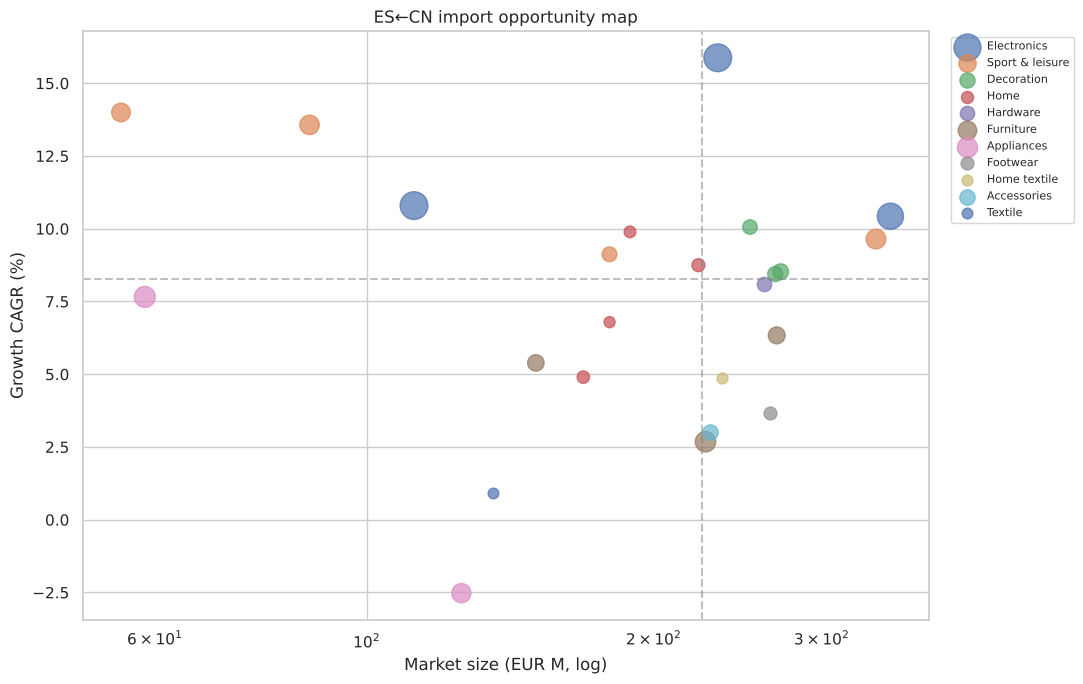

In [6]:
fig, ax = plt.subplots(figsize=(11, 7))
for group in scored["group"].unique():
    sub = scored[scored["group"] == group]
    sizes = (sub["unit_price"].fillna(sub["unit_price"].median()) * 8).clip(30, 400)
    ax.scatter(sub["value_latest"]/1e6, sub["cagr"]*100, s=sizes, alpha=0.7, label=group)

ax.axhline(scored["cagr"].median()*100, ls="--", color="grey", alpha=0.5)
ax.axvline((scored["value_latest"]/1e6).median(), ls="--", color="grey", alpha=0.5)
ax.set_xscale("log")
ax.set_xlabel("Market size (EUR M, log)")
ax.set_ylabel("Growth CAGR (%)")
ax.set_title("ES←CN import opportunity map")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## 5. Interpretation and next steps

The top-ranked categories are the candidates to explore. The next steps:

1. **Validate with real data** (switch to the Eurostat source).
2. **Cross with real margin**: add Spanish retail prices to estimate margin per sector.
3. **Go company-level**: identify who already imports these categories (bills of lading).
4. **Filter by personal fit**: among the well-scored sectors, pick the one that fits.

> The model doesn't replace human judgement — it orders the field. It says where
> to look; the final call combines data and business knowledge.

A concrete caveat the real run revealed: the top raw-score category (bicycles)
is a **false positive** — a ~€1M market whose high CAGR is noise on a tiny base.
A minimum-size filter plus the price signal help discard these. That kind of
sanity check is exactly where domain judgement meets the model.